# Data Preprocessing Assignment 1
**MSc | MDSDF402 | T1-26**

An online retailer wants to prepare customer groups for a marketing campaign. This notebook
cleans invoice lines, creates customer features and compares customer similarity. It does not
fit a segmentation model.

Source: Chen, D. (2015). *Online Retail*. UCI Machine Learning Repository.
https://doi.org/10.24432/C5BW33.
The analysis includes **all countries, 1 September to 30 November 2011**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.spatial.distance import pdist, squareform
from IPython.display import display
%matplotlib inline

# Resolve the data path from either the project root or notebooks directory.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
df = pd.read_excel(ROOT / 'Data/online+retail/Online Retail.xlsx')
# Assignment scope: use all countries and include every timestamp on 30 November.
# Keep this baseline unchanged for Tasks 1 and 2; cleaning starts from a copy.
baseline = df[(df.InvoiceDate >= '2011-09-01') & (df.InvoiceDate < '2011-12-01')].copy()
FEATURES = ['RecencyDays', 'Frequency', 'TotalSpend', 'ProductVariety']
RANDOM_SEED = 42
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
print('Data loaded for the assignment: 1 September to 30 November 2011, all countries.')
print('The baseline is unchanged; the following sections answer the seven tasks.')

Data loaded for the assignment: 1 September to 30 November 2011, all countries.
The baseline is unchanged; the following sections answer the seven tasks.


## Task 1 - Dataset understanding (2 marks)
First examine the unchanged date-filtered baseline. `info()` shows column types and non-null
counts; `describe()` summarizes quantitative values. CustomerID is excluded from numerical statistics.

In [2]:
print('\nTASK 1 | Dataset understanding')
print('I first describe the unchanged invoice-line baseline.')
# Task 1: report dimensions and column names before inspecting individual records.
print('Dataset shape (rows, columns):', baseline.shape)
print('Column names:', baseline.columns.tolist())
print('\n1.1 Column information: inferred data types and non-null counts')
print('Non-null means a value is present; CustomerID remains an identifier regardless of its numeric storage type.')
baseline.info()
print('\n1.2 First five invoice lines')
print('Each row is a product entry; several rows may legitimately share one InvoiceNo.')
display(baseline.head())
print('\n1.3 Numerical descriptive statistics: Quantity and UnitPrice')
print('Rows show count, mean, standard deviation, minimum, quartiles and maximum. CustomerID is excluded.')
display(baseline[['Quantity', 'UnitPrice']].describe())
print('\n1.4 Categorical summary: Description and Country')
print('Unique counts distinct labels; top is the most common label; freq is its number of occurrences.')
display(baseline[['Description', 'Country']].describe())
print('\n1.5 Baseline coverage: distinct invoice numbers and countries')
print('Distinct invoices:', baseline.InvoiceNo.nunique())
print('Countries:', baseline.Country.nunique())


TASK 1 | Dataset understanding
I first describe the unchanged invoice-line baseline.
Dataset shape (rows, columns): (195679, 8)
Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

1.1 Column information: inferred data types and non-null counts
Non-null means a value is present; CustomerID remains an identifier regardless of its numeric storage type.
<class 'pandas.DataFrame'>
RangeIndex: 195679 entries, 320705 to 516383
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    195679 non-null  object        
 1   StockCode    195679 non-null  object        
 2   Description  195401 non-null  object        
 3   Quantity     195679 non-null  int64         
 4   InvoiceDate  195679 non-null  datetime64[us]
 5   UnitPrice    195679 non-null  float64       
 6   CustomerID   157115 non-null  float64       
 7   Country      19567

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
320705,565080,20677,PINK POLKADOT BOWL,8,2011-09-01 08:25:00,1.2500,13509.0000,United Kingdom
320706,565080,22128,PARTY CONES CANDY ASSORTED,24,2011-09-01 08:25:00,1.2500,13509.0000,United Kingdom
320707,565081,21067,NaN,1,2011-09-01 09:03:00,0.0000,NaN,United Kingdom
320708,565082,22423,REGENCY CAKESTAND 3 TIER,2,2011-09-01 09:15:00,12.7500,13305.0000,United Kingdom
320709,565082,15060B,FAIRY CAKE DESIGN UMBRELLA,8,2011-09-01 09:15:00,3.7500,13305.0000,United Kingdom



1.3 Numerical descriptive statistics: Quantity and UnitPrice
Rows show count, mean, standard deviation, minimum, quartiles and maximum. CustomerID is excluded.


,Quantity,UnitPrice
count,195679.0000,195679.0000
mean,9.5086,4.0363
std,51.6875,48.8801
min,-4830.0000,0.0000
25%,1.0000,1.2500
50%,3.0000,2.0800
75%,11.0000,4.1300
max,12540.0000,8286.2200



1.4 Categorical summary: Description and Country
Unique counts distinct labels; top is the most common label; freq is its number of occurrences.


,Description,Country
count,195401,195679
unique,3358,30
top,PAPER CHAIN KIT 50'S CHRISTMAS,United Kingdom
freq,812,178694



1.5 Baseline coverage: distinct invoice numbers and countries
Distinct invoices: 8426
Countries: 30


### Field classification

| Field | Semantic category | Meaning |
|---|---|---|
| InvoiceNo | Identifier | Invoice key; C indicates a cancellation |
| StockCode | Identifier | Product code; letters are valid |
| CustomerID | Identifier | Customer key, even when stored as a float |
| Quantity | Numeric, discrete | Number of units on an invoice line |
| UnitPrice | Numeric, continuous | Price per unit in GBP |
| InvoiceDate | Date and time | When the invoice was recorded |
| Description | Categorical text | Product description |
| Country | Categorical | Recorded customer country |

### Why can multiple rows have the same InvoiceNo?
The dataset is recorded at invoice-line level, rather than invoice level. A single invoice
can contain multiple products, so each product appears on a separate row while sharing the
same invoice number. For example, one invoice containing three different products may occupy
three rows. Therefore, repeated invoice numbers are expected and do not automatically indicate
duplicate records.

**Observation:** The baseline contains 195,679 lines and eight columns, with 8,426 invoice
numbers across 30 countries. Negative quantities and missing customer IDs need investigation
before customer features can be calculated. Numeric storage does not make CustomerID a measure.

## Task 2 - Data quality assessment (4 marks)
Check missing values, exact duplicate copies, sales flags, text, types and outliers before cleaning.
An exact duplicate copy matches all eight fields; repeated invoice numbers alone are not duplicates.

In [3]:
print('\nTASK 2 | Missing values, duplicates and sales flags')
print('All counts below refer to the unchanged baseline, before any cleaning.')
missing = pd.DataFrame({'Missing count': baseline.isna().sum(),
                        'Missing percent': baseline.isna().mean() * 100})
print('\n2.1 Missing values by column')
print('Missing count is the number of absent values; Missing percent uses all baseline lines as the denominator.')
display(missing)
# Task 2: identical rows are duplicate copies; repeated invoice numbers alone are not.
duplicate_copies = baseline.duplicated().sum()
print('\n2.2 Exact duplicate rows: copies beyond the first identical row')
print('Exact duplicate copies beyond the first:', duplicate_copies)

cancellation = baseline.InvoiceNo.astype('string').str.startswith('C', na=False)
bad_quantity = baseline.Quantity <= 0
bad_price = baseline.UnitPrice <= 0
# Combine the flags with OR so that an overlapping line is counted only once.
sales_flags = cancellation | bad_quantity | bad_price
flag_counts = pd.Series({'Cancellation': cancellation.sum(),
                        'Quantity <= 0': bad_quantity.sum(), 'UnitPrice <= 0': bad_price.sum(),
                        'Any sales flag': sales_flags.sum()}, name='Lines')
print('\n2.3 Cancellation and non-positive-value counts')
print('These flags can overlap. Any sales flag is the union, not the sum of the first three counts.')
display(flag_counts.to_frame())


TASK 2 | Missing values, duplicates and sales flags
All counts below refer to the unchanged baseline, before any cleaning.

2.1 Missing values by column
Missing count is the number of absent values; Missing percent uses all baseline lines as the denominator.


,Missing count,Missing percent
InvoiceNo,0,0.0000
StockCode,0,0.0000
Description,278,0.1421
Quantity,0,0.0000
InvoiceDate,0,0.0000
UnitPrice,0,0.0000
CustomerID,38564,19.7078
Country,0,0.0000



2.2 Exact duplicate rows: copies beyond the first identical row
Exact duplicate copies beyond the first: 2506

2.3 Cancellation and non-positive-value counts
These flags can overlap. Any sales flag is the union, not the sum of the first three counts.


,Lines
Cancellation,3081
Quantity <= 0,3462
UnitPrice <= 0,664
Any sales flag,3745


**Observation:** There are 38,564 missing CustomerIDs (19.71%) and 278 missing descriptions
(0.14%). Missing IDs prevent reliable customer aggregation. Missing descriptions limit product
interpretation but do not necessarily prevent variety calculation using StockCode.

The 3,081 cancellation lines, 3,462 non-positive quantity lines and 664 non-positive price lines
**overlap**. Their union contains 3,745 lines, so adding the separate counts would overstate removals.

In [4]:
print('\nTASK 2 | Text consistency and type validity')
print('I inspect observed formatting and value issues without changing the baseline.')
text_rows = []
for col in ['Description', 'StockCode', 'Country']:
    text = baseline[col].astype('string')
    text_rows.append([col, (text != text.str.strip()).sum(), (text.str.strip() == '').sum()])
text_check = pd.DataFrame(text_rows, columns=['Field', 'Outer whitespace', 'Blank strings'])
print('\n2.4 Text-format checks by field')
print('Outer whitespace counts leading/trailing spaces; Blank strings counts values containing no text after trimming.')
display(text_check)
description = baseline.Description.astype('string')
print('\nObserved description examples: quotation marks reveal trailing spaces')
print('Whitespace examples:', description[description != description.str.strip()].drop_duplicates().head(2).tolist())

# Audit capitalization without changing product identifiers.
codes = baseline.StockCode.astype('string')
unique_codes = codes.drop_duplicates()
case_groups = unique_codes.groupby(unique_codes.str.upper()).size()
variant_keys = case_groups[case_groups > 1].index
case_lines = codes.str.upper().isin(variant_keys).sum()
print('\nStock-code capitalization: observed groups and affected invoice lines')
print('Stock-code capitalization variant groups:', len(variant_keys), '| affected lines:', case_lines)
print('Example variants:', unique_codes[unique_codes.str.upper().isin(variant_keys[:2])].tolist())

# Task 2: check known IDs for finite, positive integer values, not continuous magnitudes.
# Alphanumeric StockCodes are valid product identifiers and are not forced to numeric.
ids = pd.to_numeric(baseline.CustomerID, errors='coerce')
invalid_ids = baseline.CustomerID.notna() & (~np.isfinite(ids) | (ids <= 0) | (ids % 1 != 0))
type_check = pd.Series({
    'Invalid non-null CustomerID': invalid_ids.sum(),
    'Unexpected invoice format': (~baseline.InvoiceNo.astype('string').str.fullmatch(r'C?[0-9]+', na=False)).sum(),
    'Missing/blank StockCode': baseline.StockCode.isna().sum() + (codes.str.strip() == '').sum(),
    'Invalid numeric Quantity/UnitPrice': (~np.isfinite(baseline[['Quantity', 'UnitPrice']])).any(axis=1).sum(),
    'Missing InvoiceDate': baseline.InvoiceDate.isna().sum()}, name='Lines')
print('\n2.5 Type and value validity checks')
print('Lines is the number failing each check. Zero means no unexpected values were found for that check.')
display(type_check.to_frame())


TASK 2 | Text consistency and type validity
I inspect observed formatting and value issues without changing the baseline.

2.4 Text-format checks by field
Outer whitespace counts leading/trailing spaces; Blank strings counts values containing no text after trimming.


,Field,Outer whitespace,Blank strings
0,Description,45433,0
1,StockCode,0,0
2,Country,0,0



Observed description examples: quotation marks reveal trailing spaces
Whitespace examples: ['BUTTON BOX ', 'CLAM SHELL SMALL ']

Stock-code capitalization: observed groups and affected invoice lines
Stock-code capitalization variant groups: 67 | affected lines: 5228
Example variants: ['15056N', '15056BL', '15056bl', '15056n']

2.5 Type and value validity checks
Lines is the number failing each check. Zero means no unexpected values were found for that check.


,Lines
Invalid non-null CustomerID,0
Unexpected invoice format,0
Missing/blank StockCode,0
Invalid numeric Quantity/UnitPrice,0
Missing InvoiceDate,0


**Observation:** Outer whitespace affects 45,433 descriptions. For example, `'BUTTON BOX '`
has a trailing space. StockCode has 67 capitalization-variant groups affecting 5,228 lines.
These differences are audited rather than automatically merged because codes may identify
different products. There are no blank strings in the checked fields or unexpected values in
the type checks. CustomerID is stored as a float because missing values occur, but its known
values represent integer identifiers. Valid alphanumeric StockCodes are not type errors.

In [5]:
print('\nTASK 2 | Outliers and quality summary')
print('I separate statistical extremes from values that are invalid for completed sales.')
outlier_rows = []
for col in ['Quantity', 'UnitPrice']:
    # IQR fences identify unusual values; they are not automatic deletion rules.
    q1, q3 = baseline[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((baseline[col] < lower) | (baseline[col] > upper)).sum()
    outlier_rows.append([col, lower, upper, count])
outliers = pd.DataFrame(outlier_rows, columns=['Field', 'Lower fence', 'Upper fence', 'Flagged lines'])
print('\n2.6 IQR outlier thresholds and flagged-line counts')
print('Lower/upper fences are Q1 - 1.5*IQR and Q3 + 1.5*IQR. Flagged lines fall outside these fences.')
display(outliers)

# Task 2: answer the required Issue / Field / Count / Potential impact summary.
quality_summary = pd.DataFrame([
    ['Missing values', 'CustomerID', missing.loc['CustomerID', 'Missing count'], 'Cannot assign lines reliably to customers'],
    ['Missing values', 'Description', missing.loc['Description', 'Missing count'], 'Limits product interpretation; StockCode may still support variety'],
    ['Exact duplicate copies', 'All fields', duplicate_copies, 'May inflate units and spend'],
    ['Cancellation', 'InvoiceNo', cancellation.sum(), 'Return/correction activity'],
    ['Quantity <= 0', 'Quantity', bad_quantity.sum(), 'Not positive purchase quantities'],
    ['UnitPrice <= 0', 'UnitPrice', bad_price.sum(), 'Free, adjustment or invalid-price lines'],
    ['Outer whitespace', 'Description', text_check.iloc[0, 1], 'Inconsistent description labels'],
    ['Capitalization variants', 'StockCode', case_lines, 'Risk of merging different product identifiers'],
    ['IQR outliers', 'Quantity', outliers.iloc[0]['Flagged lines'], 'Unusual values; not necessarily errors'],
    ['IQR outliers', 'UnitPrice', outliers.iloc[1]['Flagged lines'], 'Unusual values; not necessarily errors']
], columns=['Issue', 'Field', 'Count', 'Potential impact'])
quality_summary['Count'] = quality_summary['Count'].astype(int)
print('\n2.7 Data-quality summary and potential effects')
print('Counts describe each issue separately and may overlap; missing descriptions and missing customer IDs have different effects.')
display(quality_summary)


TASK 2 | Outliers and quality summary
I separate statistical extremes from values that are invalid for completed sales.

2.6 IQR outlier thresholds and flagged-line counts
Lower/upper fences are Q1 - 1.5*IQR and Q3 + 1.5*IQR. Flagged lines fall outside these fences.


,Field,Lower fence,Upper fence,Flagged lines
0,Quantity,-14.0000,26.0000,10471
1,UnitPrice,-3.0700,8.4500,12151



2.7 Data-quality summary and potential effects
Counts describe each issue separately and may overlap; missing descriptions and missing customer IDs have different effects.


,Issue,Field,Count,Potential impact
0,Missing values,CustomerID,38564,Cannot assign lines reliably to customers
1,Missing values,Description,278,Limits product interpretation; StockCode may s...
2,Exact duplicate copies,All fields,2506,May inflate units and spend
3,Cancellation,InvoiceNo,3081,Return/correction activity
4,Quantity <= 0,Quantity,3462,Not positive purchase quantities
5,UnitPrice <= 0,UnitPrice,664,"Free, adjustment or invalid-price lines"
6,Outer whitespace,Description,45433,Inconsistent description labels
7,Capitalization variants,StockCode,5228,Risk of merging different product identifiers
8,IQR outliers,Quantity,10471,Unusual values; not necessarily errors
9,IQR outliers,UnitPrice,12151,Unusual values; not necessarily errors


**Observation:** The 1.5-IQR fences flag 10,471 quantity values outside [-14, 26] and
12,151 prices outside [-3.07, 8.45]. Statistical outliers are not necessarily errors: large orders
or expensive products may be genuine. Positivity and cancellation rules are handled separately.

## Task 3 - Data cleaning (4 marks)
Create a completed-sales copy. First remove the union of sales flags, then remove unidentified
customers, then remove exact duplicate copies. Keeping the order explicit prevents double-counting.

In [6]:
print('\nTASK 3 | Cleaning decisions and their effects')
print('I apply the filters sequentially so that the removal counts do not double-count the same line.')
# Task 3: exclude cancellations and non-positive sales values together.
sales = baseline.loc[~sales_flags].copy()
# Unknown customer IDs cannot be reliably imputed for customer-level aggregation.
known_sales = sales.loc[sales.CustomerID.notna()].copy()
# Keep the first exact copy; genuine identical entries may also be removed.
cleaned = known_sales.drop_duplicates().copy()

cleaning_summary = pd.DataFrame({
    'Decision': ['Completed-sales filter', 'Remove unknown CustomerID', 'Remove exact duplicate copies'],
    'Rows before': [len(baseline), len(sales), len(known_sales)],
    'Rows after': [len(sales), len(known_sales), len(cleaned)]})
cleaning_summary['Rows removed'] = cleaning_summary['Rows before'] - cleaning_summary['Rows after']
print('\n3.1 Before-and-after cleaning counts')
print('Each row shows one sequential decision: Rows before, Rows after and Rows removed at that step.')
display(cleaning_summary)

# Financial effect of the three main exclusions; amounts are signed line values.
line_values = [(frame.Quantity * frame.UnitPrice).sum() for frame in [baseline, sales, known_sales, cleaned]]
financial_impact = pd.DataFrame({'Decision': cleaning_summary.Decision,
                               'Signed GBP excluded': np.array(line_values[:-1]) - np.array(line_values[1:])})
print('\n3.2 Financial effect of major exclusions: signed GBP')
print('Signed GBP excluded is the sum removed at each step. A negative amount means the retained total increases.')
display(financial_impact)

# Task 3: trim outer whitespace, while preserving product-code case and internal characters.
before_text = cleaned.Description.astype('string')
after_text = before_text.str.strip()
changed_text = before_text.ne(after_text).fillna(False)
print('\n3.3 Description normalization: number of changed lines and actual examples')
print('Descriptions trimmed:', changed_text.sum())
print('Before/after description examples (no rows or spend removed by trimming):')
display(pd.DataFrame({'Before': before_text[changed_text], 'After': after_text[changed_text]}).drop_duplicates().head(2))
cleaned['Description'] = after_text
cleaned['InvoiceNo'] = cleaned.InvoiceNo.astype('string').str.strip()
cleaned['StockCode'] = cleaned.StockCode.astype('string').str.strip()
cleaned['Country'] = cleaned.Country.astype('string').str.strip()
cleaned['CustomerID'] = cleaned.CustomerID.astype('int64').astype('string')
cleaned['LineSpend'] = cleaned.Quantity * cleaned.UnitPrice

# Task 3: retain plausible positive IQR extremes; no capping or additional outlier removals.
# Check that all fields needed for customer aggregation are valid.
assert not invalid_ids.any(), 'Investigate invalid known customer IDs before conversion'
assert cleaned.CustomerID.notna().all()
assert (cleaned.Quantity > 0).all() and (cleaned.UnitPrice > 0).all()
assert cleaned.InvoiceNo.str.fullmatch(r'[0-9]+').all()  # Also excludes cancellations.
assert cleaned.StockCode.notna().all() and cleaned.StockCode.str.len().gt(0).all()
assert cleaned.InvoiceDate.notna().all() and np.isfinite(cleaned.LineSpend).all()
print('\n3.4 Cleaned-data validation: all required assertions passed')
print('Cleaned rows:', len(cleaned), '| completed-sales spend:', round(cleaned.LineSpend.sum(), 2))
print('Spend above is completed-sales purchase value in GBP, not net revenue after returns.')


TASK 3 | Cleaning decisions and their effects
I apply the filters sequentially so that the removal counts do not double-count the same line.

3.1 Before-and-after cleaning counts
Each row shows one sequential decision: Rows before, Rows after and Rows removed at that step.


,Decision,Rows before,Rows after,Rows removed
0,Completed-sales filter,195679,191934,3745
1,Remove unknown CustomerID,191934,154113,37821
2,Remove exact duplicate copies,154113,151630,2483



3.2 Financial effect of major exclusions: signed GBP
Signed GBP excluded is the sum removed at each step. A negative amount means the retained total increases.


,Decision,Signed GBP excluded
0,Completed-sales filter,-170917.2600
1,Remove unknown CustomerID,569091.2500
2,Remove exact duplicate copies,11436.2900



3.3 Description normalization: number of changed lines and actual examples
Descriptions trimmed: 35554
Before/after description examples (no rows or spend removed by trimming):


,Before,After
320718,BUTTON BOX,BUTTON BOX
320720,CLAM SHELL SMALL,CLAM SHELL SMALL



3.4 Cleaned-data validation: all required assertions passed
Cleaned rows: 151630 | completed-sales spend: 3142538.26
Spend above is completed-sales purchase value in GBP, not net revenue after returns.


**Decisions and observations:** The sequential row counts are 195,679 → 191,934 → 154,113 →
151,630. Removing unknown customer IDs has the largest effect: 37,821 lines and £569,091.25
of otherwise-valid purchase value. IDs are not imputed because anonymous shoppers cannot be
reliably combined. Exact deduplication removes 2,483 copies and £11,436.29, but some identical
entries could be genuine; the data has no unique line key to resolve this.

Trimming changes 35,554 descriptions without removing rows or changing spend. Identifier case
is preserved. Positive statistical extremes are retained, with no capping or extra removals,
because plausible wholesale purchases should not be discarded solely by IQR rules.

The sales filter excludes signed value of **−£170,917.26**. Removing negative return/correction
values can increase the remaining sum; this is not a revenue-loss estimate. The final spend is
**£3,142,538.26**, representing completed purchases rather than net revenue after returns.

## Task 4 - Customer features and transformations (3 marks)
Aggregate to one row per customer. Recency is measured in **calendar days** to 1 December 2011.
Frequency counts distinct invoices, spend sums Quantity × UnitPrice in GBP, and variety counts
distinct StockCode values.

In [7]:
print('\nTASK 4 | Customer feature construction')
print('I aggregate the cleaned invoice lines into one row per known customer.')
reference_date=pd.Timestamp('2011-12-01')
grouped=cleaned.groupby('CustomerID',sort=True)
# Task 4: nunique counts distinct invoices and stock codes, not invoice lines.
customers=grouped.agg(LastPurchase=('InvoiceDate','max'),Frequency=('InvoiceNo','nunique'),
                       TotalSpend=('LineSpend','sum'),ProductVariety=('StockCode','nunique'))
# Normalize the last timestamp to its date so recency is measured in calendar days.
customers['RecencyDays']=(reference_date-customers.LastPurchase.dt.normalize()).dt.days
customers=customers[FEATURES].copy()
customers.index=customers.index.astype('string')
# Three transformations: log spend, standard scaling, and interpretable recency bins.
customers['Log1pTotalSpend']=np.log1p(customers.TotalSpend)
# Fit the scaler once on the four original features; reuse scaled in Tasks 5 and 6.
scaler=StandardScaler()
scaled=pd.DataFrame(scaler.fit_transform(customers[FEATURES]),index=customers.index,columns=FEATURES)
customers['RecencyBand']=pd.cut(customers.RecencyDays,bins=[0,30,60,91],
                               labels=['Recent (1-30 days)','Warm (31-60 days)','Lapsed (61-91 days)'],right=True)

print('\n4.1 Customer-table preview: first five customers')
print('CustomerID labels each row. Original features retain business units; the final two columns are transformed versions.')
display(customers.head())
print('\n4.2 Descriptive statistics for the four original customer features')
print('RecencyDays is days, Frequency is distinct invoices, TotalSpend is GBP, and ProductVariety is distinct stock codes.')
display(customers[FEATURES].describe())


TASK 4 | Customer feature construction
I aggregate the cleaned invoice lines into one row per known customer.



4.1 Customer-table preview: first five customers
CustomerID labels each row. Original features retain business units; the final two columns are transformed versions.


,RecencyDays,Frequency,TotalSpend,ProductVariety,Log1pTotalSpend,RecencyBand
CustomerID,,,,,,
12347,31,1,1294.3200,47,7.1665,Warm (31-60 days)
12348,67,1,310.0000,3,5.7398,Lapsed (61-91 days)
12349,10,1,1757.5500,73,7.4722,Recent (1-30 days)
12352,28,3,944.2300,39,6.8514,Recent (1-30 days)
12356,14,1,58.3500,2,4.0835,Recent (1-30 days)



4.2 Descriptive statistics for the four original customer features
RecencyDays is days, Frequency is distinct invoices, TotalSpend is GBP, and ProductVariety is distinct stock codes.


,RecencyDays,Frequency,TotalSpend,ProductVariety
count,2851.0000,2851.0000,2851.0000,2851.0000
mean,30.8843,2.2241,1102.2582,42.6633
std,24.1895,3.0809,4212.7696,58.4008
min,1.0000,1.0000,3.3500,1.0000
25%,10.0000,1.0000,262.1850,14.0000
50%,24.0000,1.0000,491.2000,28.0000
75%,49.0000,2.0000,995.9050,54.0000
max,91.0000,86.0000,117634.5300,1167.0000


### Log spend and standard scaling
`log1p(TotalSpend)` compresses a long right tail. Scaling puts the four original features on
comparable scales. The same fitted scaled matrix is retained for Tasks 5 and 6; logged spend
and recency bands do not replace its columns.


TASK 4 | Log transformation and standard scaling
I compare the original and transformed values to show what each transformation changes.

4.3 Spend statistics before and after log1p
Original spend is in GBP; Log1p spend is natural log(1 + TotalSpend), not an amount in GBP.


,Original spend,Log1p spend
count,2851.0000,2851.0000
mean,1102.2582,6.2468
std,4212.7696,1.0610
min,3.3500,1.4702
25%,262.1850,5.5729
50%,491.2000,6.1989
75%,995.9050,6.9047
max,117634.5300,11.6753


Spend skewness: before log1p = 19.253; after log1p = 0.342

4.4 Scaling comparison: original mean/SD versus scaled mean/SD
A scaled mean near zero and population SD near one show that the four features now have comparable scales.


,Original mean,Original population std,Scaled mean,Scaled population std
RecencyDays,30.8843,24.1853,0.0000,1.0000
Frequency,2.2241,3.0803,0.0000,1.0000
TotalSpend,1102.2582,4212.0307,-0.0000,1.0000
ProductVariety,42.6633,58.3906,0.0000,1.0000



4.5 Spending distributions: original GBP spend (left), log1p spend (right)


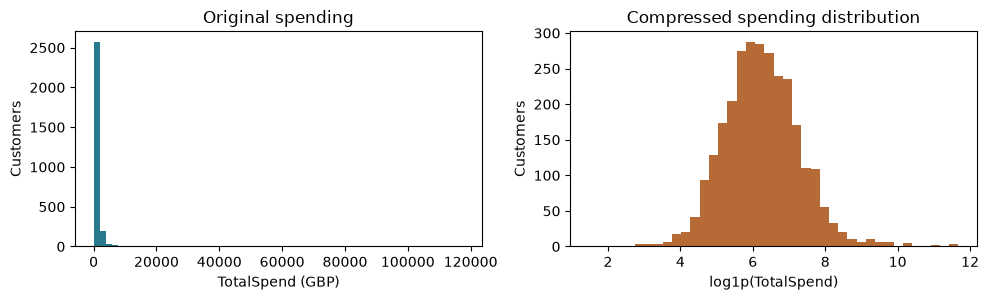

In [8]:
print('\nTASK 4 | Log transformation and standard scaling')
print('I compare the original and transformed values to show what each transformation changes.')
transform_stats=pd.DataFrame({'Original spend':customers.TotalSpend.describe(),
                             'Log1p spend':customers.Log1pTotalSpend.describe()})
print('\n4.3 Spend statistics before and after log1p')
print('Original spend is in GBP; Log1p spend is natural log(1 + TotalSpend), not an amount in GBP.')
display(transform_stats)
spend_skew=float(customers.TotalSpend.skew())
log_skew=float(customers.Log1pTotalSpend.skew())
print(f'Spend skewness: before log1p = {spend_skew:.3f}; after log1p = {log_skew:.3f}')
# Use population standard deviation (ddof=0), matching StandardScaler.
scaling_summary=pd.DataFrame({'Original mean':customers[FEATURES].mean(),
 'Original population std':customers[FEATURES].std(ddof=0),
 'Scaled mean':scaled.mean(),'Scaled population std':scaled.std(ddof=0)})
print('\n4.4 Scaling comparison: original mean/SD versus scaled mean/SD')
print('A scaled mean near zero and population SD near one show that the four features now have comparable scales.')
display(scaling_summary)
print('\n4.5 Spending distributions: original GBP spend (left), log1p spend (right)')
fig,axes=plt.subplots(1,2,figsize=(10,3.1))
axes[0].hist(customers.TotalSpend,bins=60,color='#287b8e'); axes[0].set(xlabel='TotalSpend (GBP)',ylabel='Customers',title='Original spending')
axes[1].hist(customers.Log1pTotalSpend,bins=40,color='#b66b37'); axes[1].set(xlabel='log1p(TotalSpend)',ylabel='Customers',title='Compressed spending distribution')
plt.tight_layout()
plt.savefig(ROOT / 'figures/spend_transformation.png', dpi=150)
plt.show()

**Observation:** Spend skewness falls from 19.253 to 0.342 after log1p. Median spend is
£491.20, compared with a maximum of £117,634.53, illustrating the original right tail.
Standard scaling gives each original feature mean zero and population standard deviation one.
This prevents currency units from dominating distances solely because of scale, although extreme
customers still influence the means and standard deviations.

### Recency bins and CSV export
Recent (1–30 days), Warm (31–60 days) and Lapsed (61–91 days) describe activity within this
window. Binning is easy to interpret for campaigns but loses within-band differences and creates
sharp boundaries. These labels do not establish lifetime loyalty.


TASK 4 | Recency bands and customer CSV
I summarize the bins, then check that the exported customer features match the recomputed table.

4.6 Recency-band comparison: customer counts and median GBP spend
Recent = 1-30 days, Warm = 31-60 days, Lapsed = 61-91 days before 1 December 2011.


,Customers,MedianSpend
RecencyBand,,
Recent (1-30 days),1664,648.4050
Warm (31-60 days),742,394.7700
Lapsed (61-91 days),445,336.1400



4.7 Customer counts by recency band: the bar chart compares the three groups


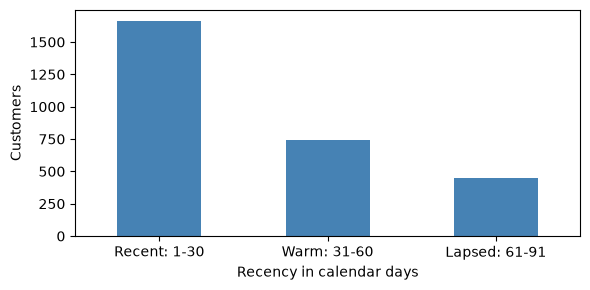


4.8 CSV validation: checking schema and recomputed feature values
Recomputed features match the existing CSV; it is preserved.
Customers: 2851
Checks passed: unique customers, valid recency, no missing features, and reconciled total spend.
CSV columns: ['CustomerID', 'RecencyDays', 'Frequency', 'TotalSpend', 'ProductVariety', 'Log1pTotalSpend', 'RecencyBand']


In [9]:
print('\nTASK 4 | Recency bands and customer CSV')
print('I summarize the bins, then check that the exported customer features match the recomputed table.')
bin_summary = customers.groupby('RecencyBand', observed=False).agg(
    Customers=('TotalSpend', 'size'), MedianSpend=('TotalSpend', 'median'))
print('\n4.6 Recency-band comparison: customer counts and median GBP spend')
print('Recent = 1-30 days, Warm = 31-60 days, Lapsed = 61-91 days before 1 December 2011.')
display(bin_summary)
print('\n4.7 Customer counts by recency band: the bar chart compares the three groups')
bin_summary.Customers.plot.bar(figsize=(6, 3), color='steelblue', rot=0)
plt.xticks(range(3), ['Recent: 1-30', 'Warm: 31-60', 'Lapsed: 61-91'])
plt.ylabel('Customers')
plt.xlabel('Recency in calendar days')
plt.tight_layout()
plt.savefig(ROOT / 'figures/recency_bins.png', dpi=150)
plt.show()

# Task 4: preserve original features and document only the two transformed columns.
export = customers.reset_index()
csv_path = ROOT / 'output/cleaned_customer_features.csv'
print('\n4.8 CSV validation: checking schema and recomputed feature values')
if csv_path.exists():
    existing = pd.read_csv(csv_path, dtype={'CustomerID': 'string'})
    pd.testing.assert_frame_equal(existing, export.assign(RecencyBand=export.RecencyBand.astype('str')),
                                  check_dtype=False, rtol=1e-12)
    print('Recomputed features match the existing CSV; it is preserved.')
else:
    export.to_csv(csv_path, index=False)
assert customers.index.is_unique and customers.RecencyDays.between(1, 91).all()
assert np.isclose(customers.TotalSpend.sum(), cleaned.LineSpend.sum())
assert customers.notna().all().all()
print('Customers:', len(customers))
print('Checks passed: unique customers, valid recency, no missing features, and reconciled total spend.')
print('CSV columns:', export.columns.tolist())

**Observation:** The CSV has 2,851 unique customers: 1,664 Recent, 742 Warm and 445 Lapsed.
Its seven columns retain CustomerID and the four original features. The two additional columns
are **Log1pTotalSpend**, the natural log of 1 + GBP spend, and **RecencyBand**, defined above.
CustomerID is a label, not a numeric feature. Recalculation matches the existing CSV.

## Task 5 - Data reduction (3 marks)
Both methods start with the **same four-column standardized matrix**, excluding IDs, log spend
and recency bands. Correlation removal keeps recognizable business variables; PCA constructs
orthogonal combinations and trades interpretability for variance compression. Neither removes customers.

For correlation removal use absolute Pearson correlation **> 0.85**. In the fixed feature order
RecencyDays, Frequency, TotalSpend, ProductVariety, keep the first feature and reject a later
feature only when its correlation with an already retained feature exceeds the threshold.
If no pair exceeds it, retain all features.


TASK 5 | Comparing correlation removal and PCA
Both methods start with the same four standardized original features; CustomerID is excluded.

5.1 Pearson correlation matrix for the starting features
Values range from -1 to 1; I use absolute correlation greater than 0.85 to identify redundancy.


,RecencyDays,Frequency,TotalSpend,ProductVariety
RecencyDays,1.0000,-0.2928,-0.1300,-0.2409
Frequency,-0.2928,1.0000,0.6012,0.6735
TotalSpend,-0.1300,0.6012,1.0000,0.4078
ProductVariety,-0.2409,0.6735,0.4078,1.0000



5.2 Correlation-based feature-removal decision
Retained: ['RecencyDays', 'Frequency', 'TotalSpend', 'ProductVariety'] | removed: []

Features removed under the correlation rule
An empty table means no feature met the threshold; all four are retained and no dimensional reduction occurs.


,Removed feature,Earlier retained feature,Correlation



5.3 PCA explained variance: individual and cumulative proportions
Multiply the proportions by 100 for percentages; the retained components must reach at least 90% cumulatively.


,Component,Explained variance,Cumulative variance
0,PC1,0.5626,0.5626
1,PC2,0.2253,0.7879
2,PC3,0.1446,0.9326
3,PC4,0.0674,1.0000



5.4 PCA coefficient table: contribution of each standardized feature
Rows are original features; columns are components. Larger absolute coefficients indicate a stronger contribution; signs give direction.


,PC1,PC2,PC3,PC4
RecencyDays,-0.2983,0.9230,-0.2265,0.0878
Frequency,0.6036,0.0992,-0.0857,0.7864
TotalSpend,0.4991,0.3670,0.7011,-0.3530
ProductVariety,0.5454,0.0592,-0.6707,-0.4992



5.5 Reduction comparison: rows, feature counts and information tradeoffs
Compare before/after dimensions and what each method retains or loses; neither method removes customer rows.


,Reduction method,Rows before,Features before,Rows after,Features after,Information retained,Information lost
0,Correlation removal,2851,4,2851,4,"Original meaning of RecencyDays, Frequency, To...",No columns removed; no dimensional reduction
1,PCA,2851,4,2851,3,93.2552% of standardized variance,6.7448% variance and direct business-unit inte...



5.6 Reduction charts: correlations (left), individual/cumulative PCA variance (right)
The dashed line marks the 90% variance target.


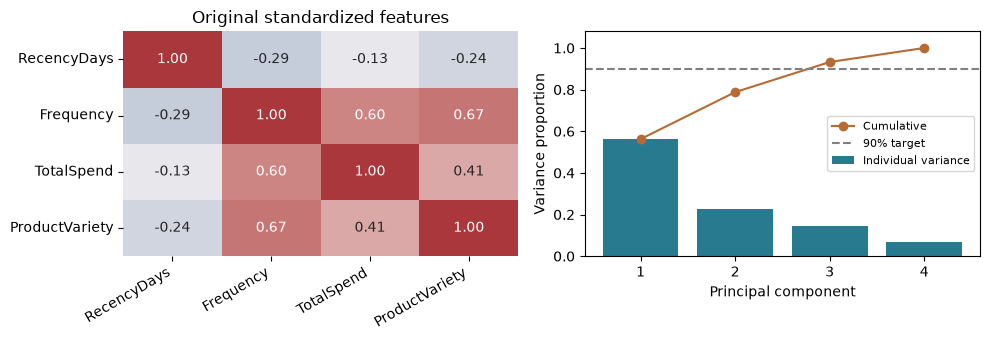

In [10]:
print('\nTASK 5 | Comparing correlation removal and PCA')
print('Both methods start with the same four standardized original features; CustomerID is excluded.')
correlation=scaled.corr()
print('\n5.1 Pearson correlation matrix for the starting features')
print('Values range from -1 to 1; I use absolute correlation greater than 0.85 to identify redundancy.')
display(correlation)
threshold=0.85
retained,removed,removal_reasons=[],[],[]
# Deterministic selection: compare each later feature only with features already retained.
for feature in FEATURES:
    conflicts=[prior for prior in retained if abs(correlation.loc[feature,prior])>threshold]
    if conflicts:
        removed.append(feature)
        removal_reasons.append([feature,conflicts[0],float(correlation.loc[feature,conflicts[0]])])
    else:
        retained.append(feature)
selected=scaled[retained]
print('\n5.2 Correlation-based feature-removal decision')
print('Retained:',retained,'| removed:',removed)
print('\nFeatures removed under the correlation rule')
print('An empty table means no feature met the threshold; all four are retained and no dimensional reduction occurs.')
display(pd.DataFrame(removal_reasons,columns=['Removed feature','Earlier retained feature','Correlation']))

# Task 5: PCA uses exactly the same scaled matrix as correlation removal.
pca=PCA(svd_solver='full')
scores=pca.fit_transform(scaled)
variance=pca.explained_variance_ratio_
cumulative=np.cumsum(variance)
# Select the minimum number of components whose cumulative variance reaches 90%.
n_components=int(np.searchsorted(cumulative,0.90)+1)
reduced_pca=scores[:,:n_components]
variance_table=pd.DataFrame({'Component':[f'PC{i+1}' for i in range(4)],
                             'Explained variance':variance,'Cumulative variance':cumulative})
loadings=pd.DataFrame(pca.components_.T,index=FEATURES,columns=[f'PC{i+1}' for i in range(4)])
print('\n5.3 PCA explained variance: individual and cumulative proportions')
print('Multiply the proportions by 100 for percentages; the retained components must reach at least 90% cumulatively.')
display(variance_table)
print('\n5.4 PCA coefficient table: contribution of each standardized feature')
print('Rows are original features; columns are components. Larger absolute coefficients indicate a stronger contribution; signs give direction.')
display(loadings)
comparison=pd.DataFrame([
 ['Correlation removal',len(scaled),4,len(selected),len(retained),
  'Original meaning of '+', '.join(retained),
  'Unique variation in '+', '.join(removed) if removed else 'No columns removed; no dimensional reduction'],
 ['PCA',len(scaled),4,len(reduced_pca),n_components,
  f'{cumulative[n_components-1]:.4%} of standardized variance',
  f'{1-cumulative[n_components-1]:.4%} variance and direct business-unit interpretation']],
 columns=['Reduction method','Rows before','Features before','Rows after','Features after',
          'Information retained','Information lost'])
print('\n5.5 Reduction comparison: rows, feature counts and information tradeoffs')
print('Compare before/after dimensions and what each method retains or loses; neither method removes customer rows.')
display(comparison)
print('\n5.6 Reduction charts: correlations (left), individual/cumulative PCA variance (right)')
print('The dashed line marks the 90% variance target.')
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
sns.heatmap(correlation,annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='vlag',ax=axes[0],cbar=False)
axes[0].set_xticklabels(axes[0].get_xticklabels(),rotation=30,ha='right'); axes[0].set_title('Original standardized features')
axes[1].bar(range(1,5),variance,label='Individual variance',color='#287b8e')
axes[1].plot(range(1,5),cumulative,'o-',color='#b66b37',label='Cumulative')
axes[1].axhline(.9,ls='--',color='gray',label='90% target')
axes[1].set(xticks=range(1,5),xlabel='Principal component',ylabel='Variance proportion',ylim=(0,1.08))
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(ROOT / 'figures/reduction.png', dpi=150)
plt.show()

**Observation:** At the selected correlation threshold (>0.85), no features are sufficiently
correlated to justify removal. All four features are retained, so this method **does not reduce
dimensionality** on these data. No feature is removed simply to produce a reduction result.

PCA retains **three components**, explaining **93.2552%** of standardized variance; the first two
explain only 78.7948%. Customer rows remain unchanged. PCA combines all four features, losing
6.7448% of variance and the direct meanings of individual business variables. The first component
largely summarizes purchase activity; component coefficients are shown above. A component is harder
to describe to marketers than a value such as number of invoices, and high variance is not proof
of marketing usefulness.

## Task 6 - Proximity measures (2 marks)
Sample 20 distinct customers without replacement using **seed 42**. Use the same four original
features standardized in Task 4 for both distances. Euclidean distance is the square root of the
sum of squared coordinate differences; Manhattan distance sums their absolute values. IDs label
rows and columns only. These comparisons use the full scaled matrix, not either reduced matrix.

In [11]:
print('\nTASK 6 | Customer similarity using two distance measures')
print('I compare the same 20 distinct customers using the same four standardized features.')
# Task 6: reproducible sampling without replacement; IDs are labels, never distance inputs.
sample=scaled.sample(n=20,replace=False,random_state=RANDOM_SEED)
print('\n6.1 Reproducible sample: seed and selected customer IDs')
print('Random seed:',RANDOM_SEED,'| customer sample:',sample.index.tolist())
euclidean=pd.DataFrame(squareform(pdist(sample.to_numpy(),metric='euclidean')),
                        index=sample.index,columns=sample.index)
manhattan=pd.DataFrame(squareform(pdist(sample.to_numpy(),metric='cityblock')),
                       index=sample.index,columns=sample.index)
print('\n6.2 Complete 20 x 20 Euclidean distance matrix')
print('Rows and columns are CustomerIDs. Smaller values indicate greater similarity; diagonal zeros are self-comparisons.')
with pd.option_context('display.max_columns',None,'display.max_rows',None,'display.width',250,'display.float_format','{:.6f}'.format):
    display(euclidean.round(6))
print('\n6.3 Complete 20 x 20 Manhattan distance matrix')
print('This uses the same customers and feature order; only the distance definition changes.')
with pd.option_context('display.max_columns',None,'display.max_rows',None,'display.width',250,'display.float_format','{:.6f}'.format):
    display(manhattan.round(6))

def nearest_pairs(matrix,metric):
    # Strict upper triangle: exclude self-pairs and count each unordered pair once.
    i,j=np.triu_indices(len(matrix),k=1)
    values=matrix.to_numpy()[i,j]
    minimum=values.min()
    # Report every nearest pair within the stated floating-point tolerance.
    tied=np.isclose(values,minimum,rtol=1e-9,atol=1e-12)
    return pd.DataFrame([[metric,str(matrix.index[a]),str(matrix.index[b]),float(v)]
                         for a,b,v in zip(i[tied],j[tied],values[tied])],
                        columns=['Metric','Customer A','Customer B','Distance'])
nearest=pd.concat([nearest_pairs(euclidean,'Euclidean'),nearest_pairs(manhattan,'Manhattan')],ignore_index=True)
print('\n6.4 Closest non-self customer pairs for each metric')
print('Every tied minimum is included. One row per metric means there is no tied closest pair under that metric.')
display(nearest)
print('Tie tolerance: rtol=1e-9, atol=1e-12. Upper triangle only: 190 unordered pairs.')
pair_ids=list(dict.fromkeys(nearest['Customer A'].tolist()+nearest['Customer B'].tolist()))
pair_original=customers.loc[pair_ids,FEATURES]
print('\n6.5 Original customer features for the nearest-pair customers')
print('These are business-unit values from the exported customer table, allowing the distance results to be interpreted.')
display(pair_original)
pair=nearest.iloc[0]
contributions=pd.DataFrame({'Customer A':customers.loc[pair['Customer A'],FEATURES],
                            'Customer B':customers.loc[pair['Customer B'],FEATURES],
                            'Absolute standardized difference':
                 (sample.loc[pair['Customer A']]-sample.loc[pair['Customer B']]).abs()})
print('\n6.6 Explaining the Euclidean closest pair feature by feature')
print('Customer A and Customer B are the first Euclidean pair above. The last column is the absolute difference in standardized units.')
display(contributions)

for matrix in [euclidean, manhattan]:
    assert matrix.shape == (20, 20) and matrix.index.is_unique
    assert np.allclose(matrix, matrix.T) and np.allclose(np.diag(matrix), 0)
print('\n6.7 Distance checks passed: both matrices are 20 x 20, symmetric, with zero diagonals.')


TASK 6 | Customer similarity using two distance measures
I compare the same 20 distinct customers using the same four standardized features.

6.1 Reproducible sample: seed and selected customer IDs
Random seed: 42 | customer sample: ['15603', '12987', '15436', '14514', '16722', '17221', '13169', '17865', '13860', '12691', '13539', '14416', '14495', '14581', '17594', '17668', '15264', '17034', '16012', '16987']

6.2 Complete 20 x 20 Euclidean distance matrix
Rows and columns are CustomerIDs. Smaller values indicate greater similarity; diagonal zeros are self-comparisons.


CustomerID,15603,12987,15436,14514,16722,17221,13169,17865,13860,12691,13539,14416,14495,14581,17594,17668,15264,17034,16012,16987
CustomerID,,,,,,,,,,,,,,,,,,,,
15603,0.000000,0.295577,3.593609,0.851027,2.846735,1.801694,0.627235,3.493837,2.939802,2.099682,0.381160,2.348025,1.158265,2.574819,0.667217,1.657306,0.686403,2.612252,1.894124,1.820427
12987,0.295577,0.000000,3.303079,0.564283,2.603250,1.554472,0.430646,3.279138,2.698968,1.890742,0.497563,2.134366,0.967144,2.357214,0.631082,1.450971,0.404142,2.385489,1.633095,1.561542
15436,3.593609,3.303079,0.000000,2.762470,1.652650,2.111781,3.084940,2.323394,1.645099,2.273529,3.676165,2.163622,2.788620,2.106689,3.494050,2.480312,2.922664,1.959368,1.942817,1.979191
14514,0.851027,0.564283,2.762470,0.000000,2.105770,1.039452,0.396119,2.913701,2.202013,1.440032,1.019047,1.667730,0.635994,1.876931,0.999788,1.021726,0.167489,1.891542,1.093798,1.076016
16722,2.846735,2.603250,1.652650,2.105770,0.000000,1.337116,2.280782,1.657050,0.184348,1.075167,3.044895,0.960670,1.882409,1.180332,2.991484,1.523224,2.237719,0.825831,1.270714,1.097473
17221,1.801694,1.554472,2.111781,1.039452,1.337116,0.000000,1.183970,2.651883,1.384702,0.582170,2.040628,0.729699,0.730405,0.861008,2.032765,0.385805,1.165573,0.903402,0.179786,0.781959
13169,0.627235,0.430646,3.084940,0.396119,2.280782,1.183970,0.000000,3.132007,2.366389,1.485419,0.922967,1.730407,0.540775,1.949502,1.042399,1.033885,0.280617,1.991444,1.288434,1.307788
17865,3.493837,3.279138,2.323394,2.913701,1.657050,2.651883,3.132007,0.000000,1.751477,2.517690,3.556609,2.508837,2.971991,2.806865,3.426417,2.832691,3.020702,2.458064,2.572410,1.968145
13860,2.939802,2.698968,1.645099,2.202013,0.184348,1.384702,2.366389,1.751477,0.000000,1.101825,3.147555,0.960116,1.948894,1.144441,3.101566,1.568197,2.331697,0.795326,1.322700,1.203005



6.3 Complete 20 x 20 Manhattan distance matrix
This uses the same customers and feature order; only the distance definition changes.


CustomerID,15603,12987,15436,14514,16722,17221,13169,17865,13860,12691,13539,14416,14495,14581,17594,17668,15264,17034,16012,16987
CustomerID,,,,,,,,,,,,,,,,,,,,
15603,0.000000,0.461138,5.492645,1.293184,4.661899,2.236018,0.743639,6.637197,4.633522,2.631351,0.592637,2.933359,1.200224,2.824703,1.021218,1.783570,1.020481,3.379651,2.484449,3.112508
12987,0.461138,0.000000,5.031507,0.832046,4.200761,1.832866,0.544449,6.176058,4.172384,2.307221,0.544973,2.506473,1.162897,2.418550,0.973554,1.571890,0.559343,2.918512,2.023311,2.651369
15436,5.492645,5.031507,0.000000,4.201095,2.562661,3.256627,4.749007,4.140152,2.320451,2.861295,5.478873,2.559287,4.292422,2.667943,5.095177,3.709075,4.472164,2.122525,3.008196,3.114895
14514,1.293184,0.832046,4.201095,0.000000,3.368715,1.158791,0.549546,5.344012,3.340338,2.040043,1.279412,2.234205,1.002604,2.189752,1.133847,1.411597,0.272703,2.291979,1.335576,1.819323
16722,4.661899,4.200761,2.562661,3.368715,0.000000,2.425881,3.918260,3.050332,0.276462,2.030548,4.648127,1.728540,3.461675,1.919891,4.219545,2.878329,3.641418,1.364943,2.177450,1.549391
17221,2.236018,1.832866,3.256627,1.158791,2.425881,0.000000,1.528182,4.401179,2.397504,1.080375,2.309334,1.279627,1.035794,1.068214,2.258387,0.466488,1.339686,1.383397,0.248432,1.372659
13169,0.743639,0.544449,4.749007,0.549546,3.918260,1.528182,0.000000,5.893558,3.889883,1.887712,1.089422,2.189720,0.618449,2.113865,1.518003,1.061693,0.359538,2.636012,1.740811,2.368869
17865,6.637197,6.176058,4.140152,5.344012,3.050332,4.401179,5.893558,0.000000,3.326793,4.171236,6.623424,4.365397,5.436973,4.970223,6.194843,4.853626,5.616715,4.415275,4.152747,3.524689
13860,4.633522,4.172384,2.320451,3.340338,0.276462,2.397504,3.889883,3.326793,0.000000,2.002171,4.619750,1.700163,3.433298,1.808819,4.191168,2.849952,3.613041,1.253871,2.149072,1.521014



6.4 Closest non-self customer pairs for each metric
Every tied minimum is included. One row per metric means there is no tied closest pair under that metric.


,Metric,Customer A,Customer B,Distance
0,Euclidean,14514,15264,0.1675
1,Manhattan,17221,16012,0.2484


Tie tolerance: rtol=1e-9, atol=1e-12. Upper triangle only: 190 unordered pairs.

6.5 Original customer features for the nearest-pair customers
These are business-unit values from the exported customer table, allowing the distance results to be interpreted.


,RecencyDays,Frequency,TotalSpend,ProductVariety
CustomerID,,,,
14514,53,1,587.0900,29
17221,28,1,132.2800,30
15264,56,1,393.7400,23
16012,27,1,283.1700,40



6.6 Explaining the Euclidean closest pair feature by feature
Customer A and Customer B are the first Euclidean pair above. The last column is the absolute difference in standardized units.


,Customer A,Customer B,Absolute standardized difference
RecencyDays,53.0000,56.0000,0.1240
Frequency,1.0000,1.0000,0.0000
TotalSpend,587.0900,393.7400,0.0459
ProductVariety,29.0000,23.0000,0.1028



6.7 Distance checks passed: both matrices are 20 x 20, symmetric, with zero diagonals.


**Observation:** There are no tied minima under the stated tolerance. The Euclidean closest
pair is **14514 and 15264 (0.167489)**; the Manhattan closest pair is **17221 and 16012 (0.248432)**.

For the Euclidean pair, recency is 53 versus 56 days, frequency is one invoice each, spend is
£587.09 versus £393.74, and product variety is 29 versus 23. These values describe similar
purchase activity on the four selected measures. They do not establish similar demographics
or product preferences.

Euclidean distance squares feature differences before summing and taking a square root, giving
greater relative weight to a large single-feature gap. Manhattan distance sums absolute differences.
The different nearest pairs show that similarity depends on the chosen measure and feature
representation. The nearest pair in this sample need not be nearest among all customers.

## Task 7 - Reflection and explainability (2 marks)
The approximately 500-word reflection is included as ordinary prose in the PDF report.
It discusses the largest cleaning impact, interpretation of completed-sales spend, retained
outliers, the three-month window, scaling and PCA, and differences between distance measures.
K-Means is recommended as a possible next step, with stability checks before campaign use.
No segmentation model is fitted in this assignment.

### Report data
The following small summary supplies the report builder with the computed tables and counts.
It is not needed to use the customer CSV.

In [12]:
# Supporting export: save computed tables for the PDF; no new analysis is performed here.
import json
report_data = {
    'baseline_rows': len(baseline), 'baseline_invoices': baseline.InvoiceNo.nunique(),
    'countries': baseline.Country.nunique(), 'cleaned_rows': len(cleaned), 'customers': len(customers),
    'total_spend': cleaned.LineSpend.sum(), 'spend_skew': spend_skew, 'log_skew': log_skew,
    'retained': retained, 'removed': removed, 'n_components': n_components,
    'variance': variance.tolist(), 'cumulative': cumulative.tolist(),
    'sample_ids': sample.index.tolist()}
report_tables = {'quality': quality_summary, 'outliers': outliers, 'cleaning': cleaning_summary,
                 'financial': financial_impact, 'scaling': scaling_summary, 'bins': bin_summary,
                 'spend_stats': transform_stats, 'nearest': nearest, 'pair_original': pair_original,
                 'comparison': comparison}
for name, frame in report_tables.items():
    report_data[name] = json.loads(frame.reset_index().to_json(orient='records', double_precision=15))
(ROOT / 'output/analysis_summary.json').write_text(json.dumps(report_data, indent=2), encoding='utf-8')
print('\nSupporting export complete: computed results saved for the report builder.')


Supporting export complete: computed results saved for the report builder.
